# Pairs Trading in Crypto: A Statistical Arbitrage Case Study

*Analysis only: no trading, no money. Binance daily prices, trading period 1 January 2022 to 12 October 2026.*

I wanted to understand how pairs trading works by building it, not just reading about it.
The idea sounds almost too clean: find two coins that move together, wait until they drift
apart, bet that they come back together. So this notebook builds the full pipeline on the
100 most traded coins, then spends most of its time asking one question: **is what I see
an edge, or did I just get lucky?**

The notebook is the long version: all code, outputs and reasoning. `README.md` is the short version.

## The idea

Two coins can both wander around randomly and still be tied to each other. Think of a
person walking a dog on a long leash: both paths are unpredictable, but the distance
between them is not. It stretches and snaps back. In statistics this is called
**cointegration**: two prices that each drift, while a weighted difference of them (the
**spread**) keeps returning to its average.

If a pair behaves like that, the trade is:

- **Spread unusually wide**: sell the coin that ran ahead, buy the one that fell behind.
- **Spread back to normal**: close both.

Because one coin is bought and the other sold, a move of the whole crypto market roughly
cancels out. The bet is only on the distance between the two, not on the direction of crypto.

**A worked example.** Coins A and B, hedge ratio 1 for simplicity. Over the last 90 days
the spread `log(A) - log(B)` averaged 0 with a standard deviation of 5%. Today A is up 10%
relative to B, so the spread is +10%, which is 2 standard deviations (z = 2).

1. Sell 1 dollar of A, buy 1 dollar of B.
2. **The spread closes back to 0**: A loses about 10% relative to B. Profit is about 10 cents, whatever crypto did as a whole.
3. **The spread keeps widening** to +20%: loss of about 10 cents. This is the case where the leash broke: the relationship was never real, or it stopped being real.

Everything hinges on step 3. The spread returning is an assumption about the future, based
on how the pair behaved in the past. The whole notebook is about how much that assumption is worth.

**Search, not pick.** I don't choose pairs by hand (for example BTC and ETH). Instead, every
6 months the strategy tests all 4,950 pairs of the 100 most traded coins over the past
year and trades the ones that look most cointegrated. That means the pairs are always picked
on data from before the trading period. It also means a lot of tests, which turns out to matter.

## The maths

**1. Test for cointegration (every 6 months, on the past year).** Regress one log price on the other:

$$\log P^y_t = \alpha + \beta \log P^x_t + \varepsilon_t$$

and test whether the leftover $\varepsilon_t$ keeps returning to zero. The test (augmented
Dickey-Fuller) fits

$$\Delta \varepsilon_t = \gamma\, \varepsilon_{t-1} + \textstyle\sum_i \phi_i \Delta \varepsilon_{t-i} + u_t$$

If $\gamma < 0$, a gap today tends to shrink tomorrow: the leash. The test statistic is the
t-value of $\gamma$, so more negative means a stronger pull back. Doing this on regression
leftovers is called the **Engle-Granger** test. Its p-values are stricter than those of a
plain ADF test, because the regression already picked the $\beta$ that makes $\varepsilon$ look
as stable as possible. (statsmodels `coint` handles this.)

**2. Pick pairs.** For each coin, keep the partner with the most negative statistic, if $p < 0.05$.

**3. Signal (daily, using the past 90 days only).**

$$\beta_t = \frac{\mathrm{Cov}_{90}(\log P^x, \log P^y)}{\mathrm{Var}_{90}(\log P^x)}, \qquad
\alpha_t = \overline{\log P^y} - \beta_t\, \overline{\log P^x}$$

$$s_t = \log P^y_t - \alpha_t - \beta_t \log P^x_t, \qquad z_t = \frac{s_t - \mathrm{mean}_{90}(s)}{\mathrm{std}_{90}(s)}$$

**4. Position.** $z_t > 1$: short the spread (sell 1 unit of $y$, buy $\beta_t$ units of $x$).
$z_t < -1$: long the spread. Close when $|z_t| < 0.5$. Positions of all pairs are added up
per coin and scaled so that the absolute weights sum to 1 (gross exposure 1).

**5. Returns and costs.** With weights $w_{i,t}$ and coin returns $r_{i,t}$:

$$r^{\text{gross}}_t = \sum_i w_{i,t-1}\, r_{i,t}, \qquad
\text{TO}_t = \sum_i |w_{i,t} - w_{i,t-1}|, \qquad
r^{\text{net}}_t = r^{\text{gross}}_t - \text{TO}_t \cdot c$$

Yesterday's weights earn today's return, so no future price goes into a decision.
Turnover $\text{TO}$ is how much of the book was traded that day, and $c$ is the cost per unit traded.

**6. Multiple testing.** With 4,950 tests at $p < 0.05$, about $0.05 \times 4{,}950 \approx 248$
pairs pass by luck even if no pair is truly cointegrated. The **Benjamini-Hochberg** correction
sorts the p-values $p_{(1)} \le \dots \le p_{(m)}$ and keeps the largest $k$ with
$p_{(k)} \le \frac{k}{m}\, 0.05$. That limits the expected share of false finds among the
passes to 5%. Coins move together a lot, so the tests are not independent and 248 is a rough
guide, not an exact number.

## Assumptions

- **Prices:** Binance daily closes against USDT (Tether, a coin pegged to the dollar). A trade happens at the close the signal was computed on.
- **Costs:** a flat 20 bps (0.20%) per unit of turnover, for every coin. That is roughly a 10 bps exchange fee plus 10 bps of slippage. Small coins probably cost more.
- **Shorting is free.** On Binance, shorting means borrowing on margin or using perpetual futures, and both charge interest or funding. Not modelled, so the net results are on the kind side.
- **Survivorship:** the data only has coins still listed today. Coins that collapsed and were delisted are missing, and a pair with such a coin would likely have lost money. Another reason the results are on the kind side.
- **Parameters fixed up front, not tuned:** 1 year formation, 6 month rebalance, 90 day window, entry at $|z| > 1$, exit at $|z| < 0.5$. These are common textbook values. Check 2 below shows what happens when they move.
- **Universe:** the 100 coins with the most USDT trading volume over each formation year, priced on at least 90% of its days. Stablecoins (coins pegged to a currency) and wrapped tokens (copies of another coin, like WBTC for BTC) are excluded, because they are "cointegrated" by construction.
- **Sizing:** 1 unit of $y$ against $\beta$ units of $x$, so the book is only dollar neutral when $\beta = 1$. Gross exposure is always 1 while any pair is open, so on a day with one open pair, that pair is the whole book.
- **Sharpe without a risk-free rate**, to keep it simple.

## The scorecard: what each number means

| Metric | What it says | How it is computed |
|---|---|---|
| Annual return | Average yearly gain on 1 dollar of gross exposure | mean daily return x 365 |
| Annual volatility | How much the returns swing | std of daily returns x sqrt(365) |
| Sharpe ratio | Return per unit of swing. 0 = nothing, around 1 = good, above 2 = suspicious | return / volatility |
| Max drawdown | Worst fall from a peak to a later low | min of wealth / running peak - 1 |
| Longest drawdown | Longest stretch spent below a previous peak, in days | |
| Turnover per day | Share of the book traded per day. 2 = the whole book replaced | sum of absolute weight changes |
| Holding period | Average days a position is held. Opening and closing a full book is a turnover of 2 | 2 / mean turnover |
| Correlation with BTC | Does it just follow the market? A market neutral strategy should be near 0 | |
| Information ratio vs BTC | Sharpe of what is left after removing the BTC exposure (rolling 1 year beta) | |
| Breakeven cost | The cost at which net return is exactly 0 | gross return / turnover |

Crypto trades every day, so the year has 365 days, not 252.

In [1]:
import itertools
import os
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from statsmodels.tsa.stattools import coint

REFRESH = False  # True: download the prices again instead of reading data/
DATA, API = "data", "https://api.binance.com/api/v3"

FIRST_TRADE = pd.Timestamp("2022-01-01")
FORMATION, REBALANCE = pd.DateOffset(years=1), pd.DateOffset(months=6)
N_COINS, ALPHA = 100, 0.05            # universe size, significance level of the pair test
ENTRY, EXIT, WINDOW = 1.0, 0.5, 90    # z-score to open, z-score to close, rolling window in days
COST_BPS = 20                         # all-in cost per unit of turnover

## Data

Daily close and USDT volume for every coin traded against USDT on Binance, from Binance's
public API (no key needed). About 500 coins, daily since August 2017. The first run
downloads into `data/` (about 2 minutes), later runs read from there. Set `REFRESH = True`
to download again. `data/` is not in the repository, so a fresh run gets newer data and
slightly different numbers.

In [2]:
def get(url, **params):
    """GET with a few retries, because a bulk download hits the odd timeout."""
    for attempt in range(5):
        try:
            return requests.get(url, params=params, timeout=30).json()
        except requests.RequestException:
            time.sleep(2 ** attempt)
    raise RuntimeError(f"failed: {url} {params}")


def binance_daily(symbol):
    """All closed daily candles of one Binance spot pair: close and volume in USDT."""
    rows, start = [], 0
    while True:
        batch = get(f"{API}/klines", symbol=symbol, interval="1d", startTime=start, limit=1000)
        rows += batch
        if len(batch) < 1000:
            break
        start = batch[-1][0] + 1
    rows = [r for r in rows if r[6] < time.time() * 1000]  # drop today's unfinished candle
    table = pd.DataFrame(rows, columns=range(12)).iloc[:, [0, 4, 7]].astype(float)
    table.columns = ["date", "close", "volume"]
    table.index = pd.to_datetime(table.pop("date"), unit="ms")
    return table


def load_prices():
    """Daily close and USDT volume of every coin traded against USDT on Binance."""
    path_px, path_vol = f"{DATA}/closes.csv", f"{DATA}/volumes.csv"
    if REFRESH or not os.path.exists(path_px):
        os.makedirs(DATA, exist_ok=True)
        info = get(f"{API}/exchangeInfo", permissions="SPOT")
        symbols = [s["symbol"] for s in info["symbols"] if s["quoteAsset"] == "USDT" and s["status"] == "TRADING"]
        with ThreadPoolExecutor(8) as pool:
            tables = dict(zip([s[:-4] for s in symbols], pool.map(binance_daily, symbols)))
        pd.DataFrame({c: t["close"] for c, t in tables.items()}).to_csv(path_px)
        pd.DataFrame({c: t["volume"] for c, t in tables.items()}).to_csv(path_vol)
    return (pd.read_csv(path_px, index_col=0, parse_dates=True),
            pd.read_csv(path_vol, index_col=0, parse_dates=True))


px, vol = load_prices()
print(f"{px.shape[1]} coins, {px.index.min():%Y-%m-%d} to {px.index.max():%Y-%m-%d}")

507 coins, 2017-08-17 to 2026-10-12


## The universe

The top 100 is re-ranked at every rebalance date, using only the formation year before it.
Ranking by today's volume would pick coins we already know survived and grew, which is
look-ahead bias.

In [3]:
STABLE = {"USDC", "BUSD", "TUSD", "FDUSD", "DAI", "USDP", "PAX", "UST", "USDE", "XUSD", "USD1", "PYUSD",
          "RLUSD", "BFUSD", "AEUR", "EUR", "EURI", "GBP", "AUD", "TRY", "BRL", "SUSD", "U"}
WRAPPED = {"WBTC", "WBETH", "BETH", "STETH", "WSTETH", "BNSOL", "PAXG", "XAUT"}


def formation(start):
    return slice(start - FORMATION, start - pd.Timedelta(days=1))


def top_coins(start, n=N_COINS):
    """The n coins with the most USDT volume over the formation year, priced on >= 90% of its days."""
    p, v = px.loc[formation(start)], vol.loc[formation(start)]
    ok = (p.notna().mean() >= 0.9) & ~p.columns.isin(STABLE | WRAPPED)
    ok &= np.log(p).diff().std() > 0.005  # catches any stablecoin the list missed
    return v.loc[:, ok].sum().nlargest(n).index.tolist()


starts = pd.date_range(FIRST_TRADE, px.index[-1], freq="6MS")
print("number of coins with a full formation year:",
      {f"{s:%Y-%m}": len(top_coins(s, n=10_000)) for s in pd.date_range("2019-01-01", px.index[-1], freq="12MS")})
excluded = vol.loc[formation(starts[-1])].sum().nlargest(N_COINS).index.intersection(list(STABLE | WRAPPED))
print("excluded from the latest top 100:", sorted(excluded))

number of coins with a full formation year: {'2019-01': 5, '2020-01': 15, '2021-01': 52, '2022-01': 109, '2023-01': 171, '2024-01': 187, '2025-01': 229, '2026-01': 286}
excluded from the latest top 100: ['BFUSD', 'EUR', 'FDUSD', 'PAXG', 'RLUSD', 'U', 'USD1', 'USDC', 'USDE', 'XAUT', 'XUSD']


**What the numbers say.** Survivorship bias decides the start date. Of today's coins, only 5
have a full year of history in 2018 and 52 in 2020. Back then Binance listed many other
coins, but the delisted ones are no longer available. A "top 100" before 2022 would be a top 5
to top 52. So trading starts on 1 January 2022 (formation year 2021), the first date with a
real top 100. The stablecoins and wrapped tokens filtered out are listed above, so the filter is visible.

## Step 1: the search

Every 6 months: rank the top 100, test all 4,950 pairs on the past year, and pick the best
partner per coin. The table compares the number of passes with what luck alone would give.
This takes about 3 minutes.

In [4]:
def test_pairs(coins, start):
    """Engle-Granger cointegration test of every pair of coins over the formation year."""
    logp = np.log(px.loc[formation(start), coins]).ffill()
    rows = []
    for y, x in itertools.combinations(coins, 2):
        both = logp[[y, x]].dropna()
        stat, p, _ = coint(both[y], both[x])
        rows.append((y, x, stat, p))
    return pd.DataFrame(rows, columns=["y", "x", "stat", "p"])


def pick_pairs(tests):
    """For each coin, its partner with the most negative test statistic, if p < ALPHA."""
    passed = tests[tests["p"] < ALPHA]
    best = set()
    for coin in set(passed["y"]) | set(passed["x"]):
        mine = passed[(passed["y"] == coin) | (passed["x"] == coin)]
        best.add(tuple(mine.loc[mine["stat"].idxmin(), ["y", "x"]]))
    return sorted(best)


def bh_passes(p):
    """Number of tests that pass Benjamini-Hochberg at ALPHA (false discovery rate)."""
    p = np.sort(p)
    ok = np.nonzero(p <= ALPHA * np.arange(1, len(p) + 1) / len(p))[0]
    return ok[-1] + 1 if len(ok) else 0


periods = []
for start in starts:
    end = min(start + REBALANCE - pd.Timedelta(days=1), px.index[-1])
    coins = top_coins(start)
    tests = test_pairs(coins, start)
    periods.append({"start": start, "end": end, "coins": coins, "tests": tests, "pairs": pick_pairs(tests)})

search = pd.DataFrame([{
    "pairs tested": len(p["tests"]),
    "p < 0.05": (p["tests"]["p"] < ALPHA).sum(),
    "expected by luck": round(ALPHA * len(p["tests"])),
    "pass after BH": bh_passes(p["tests"]["p"]),
    "pairs traded": len(p["pairs"]),
} for p in periods], index=[f"{p['start']:%Y-%m}" for p in periods])
search

,pairs tested,p < 0.05,expected by luck,pass after BH,pairs traded
2022-01,4950,504,248,34,76
2022-07,4950,578,248,107,88
2023-01,4950,702,248,16,78
2023-07,4950,526,248,51,81
2024-01,4950,597,248,73,88
2024-07,4950,310,248,5,77
2025-01,4950,337,248,3,76
2025-07,4950,249,248,0,71
2026-01,4950,287,248,1,82
2026-07,4950,630,248,57,79


**What the numbers say.** Every period has more passes than luck would give, but often not
many more. In the strongest period (January 2023) 702 pairs pass against 248 expected by luck.
In July 2025 it is 249 against 248: the search found exactly as much as random noise would.
After the Benjamini-Hochberg correction, between 0 and 107 pairs survive per period.

Yet the strategy trades 71 to 88 pairs every period, because the rule "best partner per coin,
p < 0.05" doesn't care how many passes were luck. Every coin with at least one lucky pass gets
a pair. So in a period like July 2025 most of the traded pairs are probably noise. Picking the
best of many tests also picks the luckiest one, so the in-sample statistics flatter every
pair a bit.

## Step 2: signals

For every traded pair: the rolling hedge ratio, the spread and its z-score. Then the
position rule from the maths section, and the weights per coin.

In [5]:
def zscores(pairs, start, end, window=WINDOW):
    """Rolling hedge ratio and z-score of the spread log(y) - alpha - beta * log(x), one column per pair."""
    hist = np.log(px.loc[start - FORMATION:end]).ffill()
    Y = hist[[y for y, _ in pairs]].set_axis(range(len(pairs)), axis=1)
    X = hist[[x for _, x in pairs]].set_axis(range(len(pairs)), axis=1)
    mean = lambda d: d.rolling(window).mean()
    beta = (mean(X * Y) - mean(X) * mean(Y)) / (mean(X * X) - mean(X) ** 2)
    spread = Y - (mean(Y) - beta * mean(X)) - beta * X
    z = (spread - mean(spread)) / spread.rolling(window).std()
    return z.loc[start:end], beta.loc[start:end]


def positions(z, entry=ENTRY, exit=EXIT):
    """+1 long the spread, -1 short the spread, 0 flat. Open beyond +-entry, hold until |z| < exit."""
    signal = np.where(z > entry, -1.0, np.where(z < -entry, 1.0, np.where(z.abs() < exit, 0.0, np.nan)))
    return pd.DataFrame(signal, index=z.index, columns=z.columns).ffill().fillna(0)


def coin_weights(pairs, start, end, entry=ENTRY, exit=EXIT, window=WINDOW):
    """Daily portfolio weight per coin: 1 unit of y against beta units of x, summed over pairs, gross 1."""
    z, beta = zscores(pairs, start, end, window)
    pos = positions(z, entry, exit)
    w = pd.concat([pos.set_axis([y for y, _ in pairs], axis=1),
                   (-pos * beta).set_axis([x for _, x in pairs], axis=1)], axis=1)
    w = w.T.groupby(level=0).sum().T
    return w.div(w.abs().sum(axis=1), axis=0).fillna(0)

One pair, to see the mechanism at work: the most cointegrated pair of the first period.

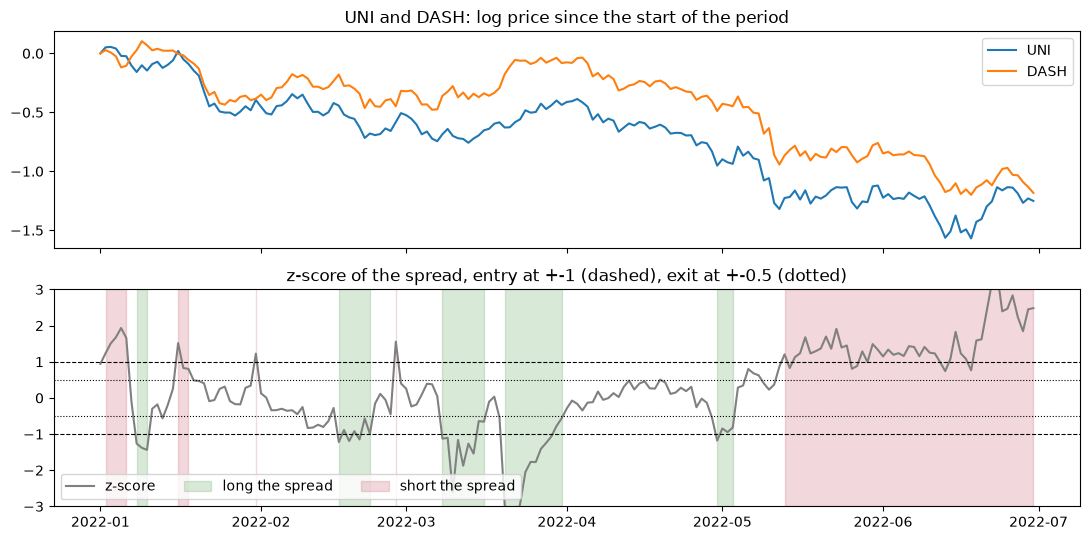

In [6]:
first = periods[0]
y, x = first["tests"].loc[first["tests"].set_index(["y", "x"]).index.isin(first["pairs"])].nsmallest(1, "stat")[["y", "x"]].iloc[0]
z, _ = zscores([(y, x)], first["start"], first["end"])
z, pos = z[0], positions(z)[0]

fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for coin in (y, x):
    ax[0].plot(np.log(px.loc[z.index, coin] / px.loc[z.index[0], coin]), label=coin)
ax[0].set(title=f"{y} and {x}: log price since the start of the period")
ax[0].legend()
ax[1].plot(z, color="grey", label="z-score")
for level, style in ((ENTRY, "--"), (EXIT, ":")):
    ax[1].axhline(level, color="black", ls=style, lw=0.8)
    ax[1].axhline(-level, color="black", ls=style, lw=0.8)
ax[1].fill_between(z.index, -3, 3, where=pos > 0, color="#66aa66", alpha=0.25, label="long the spread")
ax[1].fill_between(z.index, -3, 3, where=pos < 0, color="#cc6677", alpha=0.25, label="short the spread")
ax[1].set(title="z-score of the spread, entry at +-1 (dashed), exit at +-0.5 (dotted)", ylim=(-3, 3))
ax[1].legend(loc="lower left", ncol=3)
plt.tight_layout()

**What the plot shows.** UNI and DASH drift down together in early 2022, and the spread
swings back and forth: the trades from February to April are the textbook case, opening
beyond ±1 and closing near 0. Then from mid May the spread leaves and doesn't come back.
The strategy sits in a short spread position for the rest of the period, waiting for a
reversion that never happens. That is step 3 of the worked example: the leash broke. The
z-score also hides this a bit, because its 90 day mean and std slowly adapt to the new
level, so the position looks less extreme than it is.

## Step 3: the backtest

The 6-month blocks are stitched together into one portfolio, so a pair dropped at a
rebalance is closed and pays its cost.

In [7]:
def backtest(weights, cost_bps=COST_BPS):
    """Daily returns: yesterday's weights times today's coin returns, minus turnover times cost."""
    rets = px[weights.columns].pct_change().reindex(weights.index).fillna(0)
    gross = (weights.shift() * rets).sum(axis=1)
    turnover = weights.diff().abs().sum(axis=1)
    return pd.DataFrame({"gross": gross, "turnover": turnover, "net": gross - turnover * cost_bps * 1e-4})


def run(periods, **params):
    """Stitch the 6-month blocks together and backtest them as one portfolio."""
    w = pd.concat([coin_weights(p["pairs"], p["start"], p["end"], **params) for p in periods]).fillna(0)
    return backtest(w)


def sharpe(r):
    return r.mean() / r.std() * np.sqrt(365)


def metrics(r, turnover=None):
    """The scorecard, from daily returns (and turnover, if it is a strategy)."""
    wealth = (1 + r).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    under = drawdown < 0
    beta = r.rolling(365).cov(btc) / btc.rolling(365).var()
    resid = (r - beta.shift() * btc).dropna()  # what is left after taking out BTC exposure
    out = {
        "annual return": r.mean() * 365,
        "annual volatility": r.std() * np.sqrt(365),
        "Sharpe ratio": sharpe(r),
        "max drawdown": drawdown.min(),
        "longest drawdown (days)": under.groupby((~under).cumsum()).sum().max(),
        "correlation with BTC": r.corr(btc),
    }
    if turnover is not None:
        out |= {"information ratio vs BTC": sharpe(resid),
                "turnover per day": turnover.mean(), "holding period (days)": 2 / turnover.mean()}
    return pd.Series(out)


result = run(periods)
btc = px["BTC"].pct_change().reindex(result.index)
net = metrics(result["net"], result["turnover"])
scorecard = pd.DataFrame({
    "strategy, gross": metrics(result["gross"], result["turnover"]),
    "strategy, net": net,
    "buy and hold BTC": metrics(btc),
}).reindex(net.index)
print(f"{result.index[0]:%Y-%m-%d} to {result.index[-1]:%Y-%m-%d}, {len(result)} days")
scorecard.round(3)

2022-01-01 to 2026-10-12, 1746 days


,"strategy, gross","strategy, net",buy and hold BTC
annual return,0.040,-0.119,0.247
annual volatility,0.207,0.207,0.505
Sharpe ratio,0.195,-0.576,0.489
max drawdown,-0.391,-0.596,-0.669
longest drawdown (days),975.000,1267.000,769.000
correlation with BTC,0.221,0.223,1.000
information ratio vs BTC,-0.302,-1.099,NaN
turnover per day,0.218,0.218,NaN
holding period (days),9.162,9.162,NaN


**What the numbers say.**

- **Gross**, the strategy makes 4.0% a year with 20.7% volatility, a Sharpe of 0.20. Something, but not much.
- **Net** of 20 bps it loses 11.9% a year, a Sharpe of -0.58, and the max drawdown is 60%. It spends 1,267 days, most of the sample, below an earlier peak.
- **Turnover** is 0.22 a day, so a position is held about 9 days on average. Every unit of turnover pays 20 bps, and that adds up to about 16% a year.
- **Not market neutral:** correlation with BTC is 0.22. The book is only dollar neutral when $\beta = 1$, so some market exposure leaks in.
- **Nothing left after BTC:** the information ratio against BTC is -0.30 gross. Take out the part of the return that just follows BTC and what remains is slightly negative.
- **BTC buy and hold** over the same period: Sharpe 0.49, but with a 67% drawdown along the way.

So the strategy doesn't make money net of costs. The more interesting question is whether
the gross edge is real or luck. If it's real, it's worth thinking about cheaper execution.
If it's luck, there is nothing to make cheaper.

## Was it luck? Four checks

A backtest can look good (or, here, gross-positive) by accident. Each check below asks one
semantic question that the scorecard can't answer:

1. **Works on new data?**
2. **Works next door?** An edge is usually a hill, not a needle. Moving the parameters, the period or the coins a little should not flip the result.
3. **Survives cost?**
4. **Beats a random market?**

### Check 1: works on new data?

The design is out of sample by construction. Each 6-month block is traded with pairs chosen
on the year before it, and the parameters were fixed before looking at any result. So every
block is a fresh test. How many pass?

blocks with a positive net return: 4 of 10


,pairs,gross return,net return,BTC return
2022-01,76,0.098,0.017,-0.714
2022-07,88,0.167,0.089,-0.107
2023-01,78,0.199,0.108,0.671
2023-07,81,0.032,-0.047,0.364
2024-01,88,-0.053,-0.125,0.469
2024-07,77,-0.042,-0.128,0.465
2025-01,76,-0.146,-0.210,0.189
2025-07,71,-0.042,-0.121,-0.168
2026-01,82,0.120,0.039,-0.342
2026-07,79,-0.140,-0.191,0.354


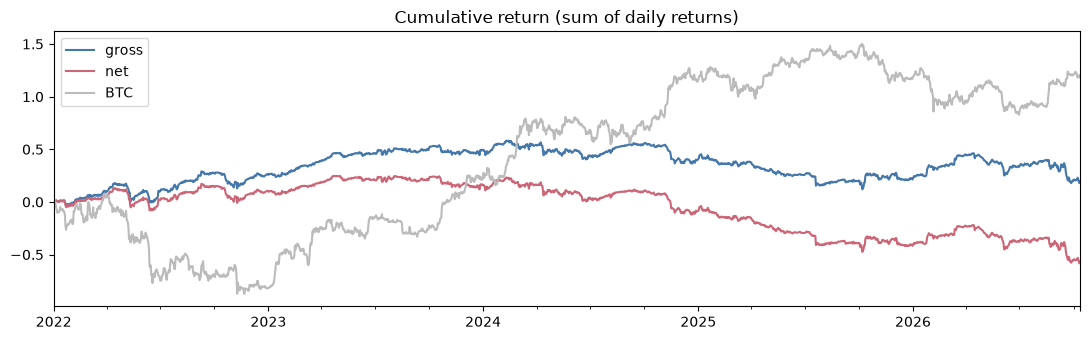

In [8]:
blocks = result.groupby(np.searchsorted([p["end"] for p in periods], result.index))
block_table = pd.DataFrame({
    "pairs": [len(p["pairs"]) for p in periods],
    "gross return": blocks["gross"].sum().values,
    "net return": blocks["net"].sum().values,
    "BTC return": btc.groupby(np.searchsorted([p["end"] for p in periods], btc.index)).sum().values,
}, index=[f"{p['start']:%Y-%m}" for p in periods])
print(f"blocks with a positive net return: {(block_table['net return'] > 0).sum()} of {len(block_table)}")
display(block_table.round(3))

ax = result[["gross", "net"]].assign(BTC=btc).cumsum().plot(figsize=(11, 3.5), color=["#4477aa", "#cc6677", "#bbbbbb"])
ax.set(title="Cumulative return (sum of daily returns)", xlabel="")
plt.tight_layout()

**What the numbers say.** 5 of 10 blocks are positive gross and 4 of 10 net (the last block
only runs to 12 October). Four of the five good blocks come early, January 2022 to December
2023. From 2024 the strategy loses in 5 of 6 blocks, before costs too. A coin flip would give
5 of 10. So "it works on new data" holds for the first two years and then mostly stops.

It's tempting to link this to the search table: three of the four blocks where the passes
were close to the luck level (July 2024 to January 2026) lost money. But January 2024 and
July 2026 had plenty of passes and lost anyway. With ten blocks I wouldn't read much into it.

### Check 2: works next door?

**Parameters.** 27 settings: window 60 / 90 / 120 days, entry 0.75 / 1 / 1.5, exit 0.2 / 0.5 / 0.7.
The full grid is shown. The best cell is never reported as the result, because picking the
best of 27 is the same luck trap as picking the best of 4,950 pairs.

net Sharpe across all 27 settings: median -0.58, range -1.24 to -0.30, positive in 0 of 27
gross Sharpe across all 27 settings: median 0.18, positive in 25 of 27


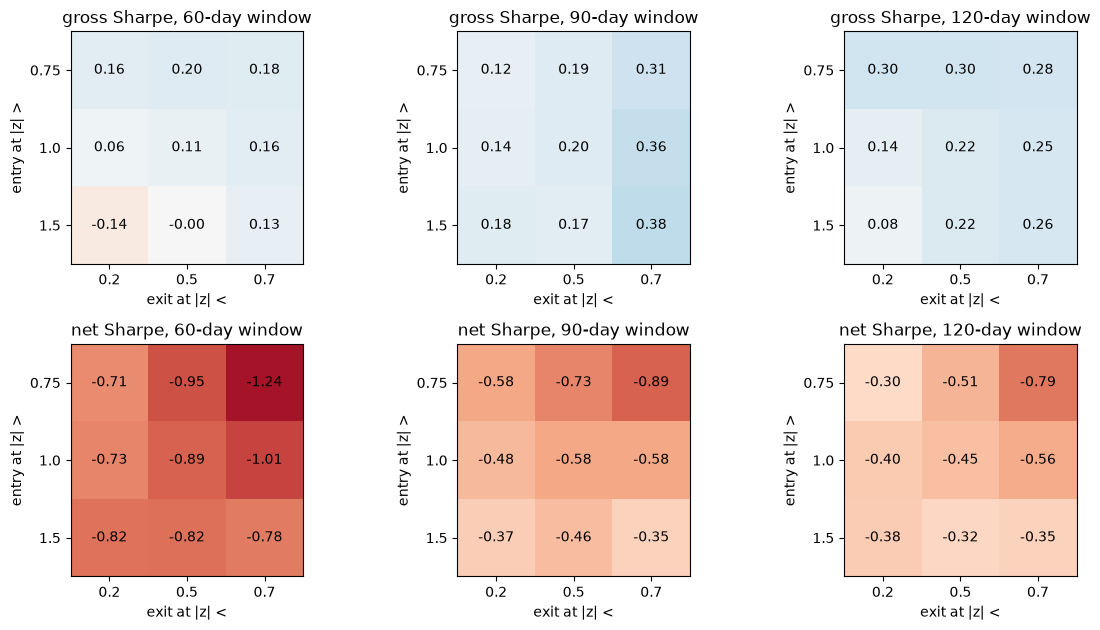

In [9]:
grid = []
for window in (60, 90, 120):
    for entry in (0.75, 1.0, 1.5):
        for exit in (0.2, 0.5, 0.7):
            r = run(periods, entry=entry, exit=exit, window=window)
            grid.append({"window": window, "entry": entry, "exit": exit, "gross": sharpe(r["gross"]), "net": sharpe(r["net"])})
grid = pd.DataFrame(grid)

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for row, col in enumerate(["gross", "net"]):
    for ax, (window, part) in zip(axes[row], grid.groupby("window")):
        table = part.pivot(index="entry", columns="exit", values=col)
        ax.imshow(table, cmap="RdBu", vmin=-1.5, vmax=1.5)
        for (i, j), v in np.ndenumerate(table.values):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center")
        ax.set(title=f"{col} Sharpe, {window}-day window", xticks=range(3), xticklabels=table.columns,
               yticks=range(3), yticklabels=table.index, xlabel="exit at |z| <", ylabel="entry at |z| >")
plt.tight_layout()
print(f"net Sharpe across all 27 settings: median {grid['net'].median():.2f}, "
      f"range {grid['net'].min():.2f} to {grid['net'].max():.2f}, positive in {(grid['net'] > 0).sum()} of 27")
print(f"gross Sharpe across all 27 settings: median {grid['gross'].median():.2f}, positive in {(grid['gross'] > 0).sum()} of 27")

**What the numbers say.** Gross, it's a hill: positive in 25 of 27 settings, from -0.14 to
0.38, with longer windows and earlier exits doing a little better. The fixed setting (90 days,
entry 1, exit 0.5) gives 0.20, right in the middle, so it wasn't a lucky pick. The small gross
edge is not a needle that only one setting finds. Net, every single setting
loses money. The result doesn't hinge on the parameters, it hinges on cost.

**Time and coins.** Sharpe per calendar year, and the same strategy run separately on the
top 50 coins and on coins 51 to 100 (pairs only within each group).

In [10]:
by_year = result.groupby(result.index.year)
display(pd.DataFrame({"gross Sharpe": by_year["gross"].apply(sharpe), "net Sharpe": by_year["net"].apply(sharpe),
                      "BTC Sharpe": btc.groupby(btc.index.year).apply(sharpe)}).round(2).T)

halves = {}
for name, ranks in {"top 50": slice(0, 50), "coins 51 to 100": slice(50, 100)}.items():
    sub = []
    for p in periods:
        group = p["coins"][ranks]
        tests = p["tests"][p["tests"]["y"].isin(group) & p["tests"]["x"].isin(group)]
        sub.append(p | {"pairs": pick_pairs(tests)})
    r = run(sub)
    halves[name] = {"gross Sharpe": sharpe(r["gross"]), "net Sharpe": sharpe(r["net"]),
                    "pairs per block": np.mean([len(p["pairs"]) for p in sub])}
pd.DataFrame(halves).round(2)

date,2022,2023,2024,2025,2026
gross Sharpe,1.18,1.46,-0.46,-0.94,-0.10
net Sharpe,0.48,0.38,-1.22,-1.66,-0.80
BTC Sharpe,-1.29,2.35,1.76,0.05,0.03


,top 50,coins 51 to 100
gross Sharpe,-0.49,0.17
net Sharpe,-1.19,-0.51
pairs per block,33.60,35.40


**What the numbers say.** Over time, it's two regimes: gross Sharpe 1.18 and 1.46 in 2022 and
2023, then negative in 2024, 2025 and 2026. Across coins, neither half works on its own: the
top 50 is negative even gross (-0.49), coins 51 to 100 slightly positive (0.17). So the edge
isn't a hill across time or coins. It lives in one period and in the mix of the full universe.
This is the clearest warning sign of the four checks.

### Check 3: survives cost?

The same gross returns, with costs from 0 to 40 bps per unit of turnover.

In [11]:
costs = [0, 5, 10, 20, 30, 40]
sweep = pd.DataFrame({
    "net Sharpe": [sharpe(result["gross"] - result["turnover"] * c * 1e-4) for c in costs],
    "net annual return": [(result["gross"] - result["turnover"] * c * 1e-4).mean() * 365 for c in costs],
}, index=pd.Index(costs, name="cost (bps)"))
breakeven = result["gross"].mean() / result["turnover"].mean() * 1e4
print(f"breakeven cost: {breakeven:.1f} bps per unit of turnover")
sweep.round(3)

breakeven cost: 5.1 bps per unit of turnover


,net Sharpe,net annual return
cost (bps),,
0,0.195,0.040
5,0.003,0.001
10,-0.190,-0.039
20,-0.576,-0.119
30,-0.962,-0.199
40,-1.349,-0.278


**What the numbers say.** The breakeven cost is 5.1 bps. At 5 bps the net return is zero,
at 10 bps it's already negative. A Binance spot taker fee alone is about 10 bps, before any
slippage and before the cost of shorting. Even a large trader with fee discounts and limit
orders would struggle to get the all-in cost below 5 bps across 100 coins, many of them small.
So no: this does not survive realistic costs, by a factor of about 4.

### Check 4: beats a random market?

Does the cointegration search add anything, or would any crypto pair do? Each of 200 draws
replaces the chosen pairs with the same number of pairs picked at random from the 4,950,
every period, and runs the same rule. This takes about 1 minute.

gross: search 0.20, random median -0.55, search beats 100% of random draws
net: search -0.58, random median -1.28, search beats 100% of random draws


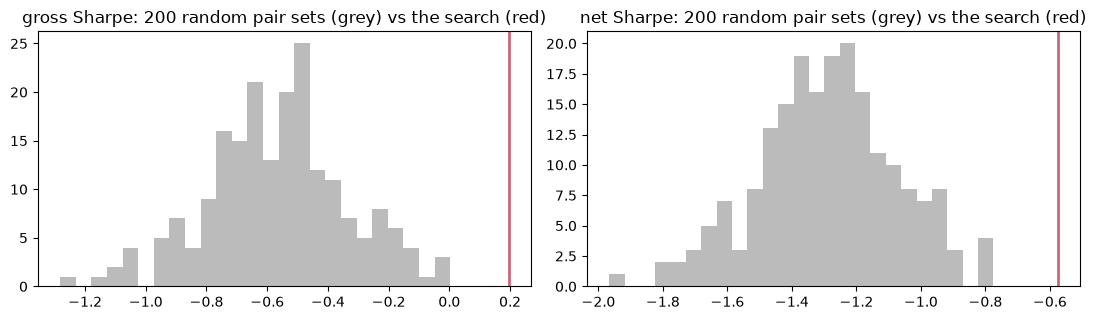

In [12]:
rng = np.random.default_rng(0)
random_sharpe = []
for draw in range(200):
    sub = [p | {"pairs": [tuple(p["tests"].iloc[i][["y", "x"]])
                          for i in rng.choice(len(p["tests"]), len(p["pairs"]), replace=False)]}
           for p in periods]
    r = run(sub)
    random_sharpe.append((sharpe(r["gross"]), sharpe(r["net"])))
random_sharpe = pd.DataFrame(random_sharpe, columns=["gross", "net"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for a, col in zip(ax, ["gross", "net"]):
    actual = sharpe(result[col])
    a.hist(random_sharpe[col], bins=25, color="#bbbbbb")
    a.axvline(actual, color="#cc6677", lw=2)
    a.set(title=f"{col} Sharpe: 200 random pair sets (grey) vs the search (red)")
    print(f"{col}: search {actual:.2f}, random median {random_sharpe[col].median():.2f}, "
          f"search beats {(random_sharpe[col] < actual).mean():.0%} of random draws")
plt.tight_layout()

**What the numbers say.** The search beats all 200 random draws, gross and net. So the
search does find something: the chosen pairs revert more reliably than random ones. But
look at where the random draws sit: a median gross Sharpe of -0.55. Betting on reversion
between random crypto pairs **loses money even before costs**. One reading is that crypto
spreads tend to keep going (trend) more often than they snap back, so a reversion bet on an
arbitrary pair is a bet against momentum. The search turns a losing rule into a slightly
winning one. That's a real effect, but it starts from below zero.

## The four checks together

| Check | Question | Result | Passed? |
|---|---|---|---|
| 1. New data | Do the fresh 6-month blocks make money? | 5 of 10 gross, 4 of 10 net. Since 2024, 5 of 6 blocks lose | No |
| 2. Next door | Do nearby settings, years and coins agree? | Parameters: gross positive in 25 of 27. Years: only 2022 and 2023. Coins: neither half works alone | Parameters yes, time and coins no |
| 3. Cost | Does it survive 20 bps? | Breakeven 5.1 bps | No |
| 4. Random market | Better than random pairs? | Beats 200 of 200, but random pairs lose gross (median -0.55) | Yes, from a low base |

## Conclusion

Pairs trading in crypto, done the textbook way on daily data, doesn't make money here.
The more interesting part is why:

- **The mechanism is real, but weak.** The search does find pairs that revert better than random ones (check 4), and the small gross edge holds up across parameter settings (check 2).
- **The edge is far too thin for the cost.** It earns about 5 bps per unit traded and the strategy trades a lot (a 9 day holding period). Costs of 20 bps turn a 4% gross year into a 12% net loss.
- **The relationships don't last.** The edge lives in 2022 and 2023 and is gone after. In 2025 the search found exactly as many pairs as luck would. A "statistically significant" cointegration over one year says little about the next six months, which is the actual bet.
- **Luck is everywhere in the pipeline.** 248 false passes per period are expected. The "best partner per coin" rule picks the luckiest ones, and nothing in the rule stops trading pure noise.

What I would try next, if I continued: trade only pairs that survive Benjamini-Hochberg (fewer
but more credible pairs), stop out a pair once its spread leaves a set range instead of
waiting forever (the UNI/DASH case), and use hourly data to see whether the reversion is
faster than daily closes show. Each of these is a new hypothesis that would need the same four checks.

## What this is not

- Not a tradable strategy, and not a claim that pairs trading can't work. It's one textbook version on one data set.
- The costs are one flat assumption. Shorting costs (margin interest, futures funding) are missing, and so are delisted coins. Both make the real result worse, not better.
- Daily closes miss everything that happens within a day. Reversion that plays out within hours is invisible here.
- The results come from 10 blocks of 6 months. That is not a lot of independent evidence, in either direction.